# Hafta 3: Keşifsel Veri Analizi (EDA)

Bu not defteri `data/processed/` altındaki sentetik Türkçe kiosk sorgu veri setini inceler. Veri, `src/kiosk_nlu/generate_dataset.py` ile (seed=42) üretilmiştir; gerçek kullanıcı verisi **değildir**.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 120)
splits = {n: pd.read_csv(f"data/processed/{n}.csv") for n in ["train", "val", "test", "test_hard"]}
for n, d in splits.items():
    print(f"{n:10s} satır={len(d):5d}  benzersiz metin={d.text.nunique():5d}")

train      satır= 1540  benzersiz metin= 1540
val        satır=  245  benzersiz metin=  245
test       satır=  280  benzersiz metin=  280
test_hard  satır=  280  benzersiz metin=  280


                    train  val  test  test_hard
intent                                         
find_facility         220   35    40         40
find_store            220   35    40         40
floor_directory       220   35    40         40
greeting_help         220   35    40         40
opening_hours         220   35    40         40
out_of_scope          220   35    40         40
recommend_category    220   35    40         40


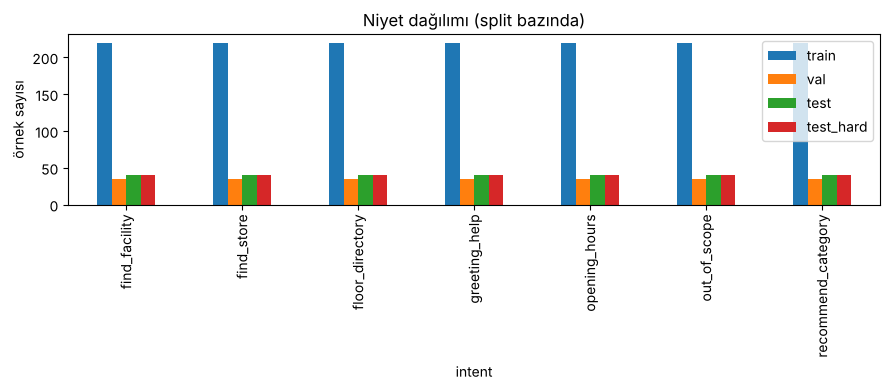

In [2]:
dist = pd.DataFrame({n: d.intent.value_counts() for n, d in splits.items()}).fillna(0).astype(int)
print(dist)
ax = dist.plot(kind="bar", figsize=(9, 4), title="Niyet dağılımı (split bazında)")
ax.set_ylabel("örnek sayısı"); plt.tight_layout(); plt.savefig("docs/week3/figures/eda_intent_dist.png", dpi=120)

      train   val  test  test_hard
mean   3.99  3.97  4.17       5.04
min    1.00  1.00  1.00       1.00
50%    4.00  4.00  4.00       5.00
max   10.00  9.00  8.00      10.00


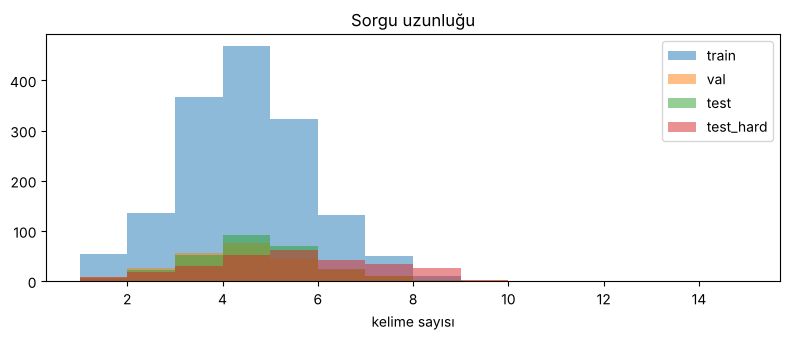

In [3]:
for n, d in splits.items():
    d["n_words"] = d.text.str.split().str.len()
print(pd.DataFrame({n: d.n_words.describe()[["mean", "min", "50%", "max"]] for n, d in splits.items()}).round(2))
fig, ax = plt.subplots(figsize=(8, 3.5))
for n, d in splits.items():
    ax.hist(d.n_words, bins=range(1, 16), alpha=0.5, label=n)
ax.set_xlabel("kelime sayısı"); ax.set_title("Sorgu uzunluğu"); ax.legend(); plt.tight_layout()
plt.savefig("docs/week3/figures/eda_length.png", dpi=120)

In [4]:
tr_chars = set("ıöüçşğİÖÜÇŞĞ")
def stats(d):
    return pd.Series({
        "Türkçe karakter içeren": d.text.apply(lambda t: any(c in tr_chars for c in t)).mean(),
        "soru/noktalama ile biten": d.text.str.contains(r"[?!.]$").mean(),
        "dolgu sözcüğü (lütfen, acaba...)": d.text.str.contains(r"lütfen|lutfen|acaba|abi|hocam|pardon").mean(),
    })
print(pd.DataFrame({n: stats(d) for n, d in splits.items()}).round(3))

                                  train    val   test  test_hard
Türkçe karakter içeren            0.645  0.657  0.625      0.571
soru/noktalama ile biten          0.382  0.380  0.400      0.282
dolgu sözcüğü (lütfen, acaba...)  0.244  0.306  0.279      0.368


In [5]:
import sys; sys.path.insert(0, "src")
stores = pd.read_csv("data/avm/stores.csv")
tr = splits["train"]
store_counts = tr[tr.entity_type == "store"].entity_value.value_counts()
print("Eğitimde görülen mağaza sayısı:", store_counts.shape[0], "/", len(stores))
print("Mağaza örnek sayısı: min", store_counts.min(), "max", store_counts.max())
print()
print("Varlık tipi dağılımı (train):")
print(tr.entity_type.fillna("yok").value_counts())
print()
print("Varlıksız niyetler:", sorted(tr[tr.entity_type.isna()].intent.unique()))

Eğitimde görülen mağaza sayısı: 36 / 36
Mağaza örnek sayısı: min 1 max 17

Varlık tipi dağılımı (train):
entity_type
yok         524
store       356
floor       220
category    220
facility    220
Name: count, dtype: int64

Varlıksız niyetler: ['greeting_help', 'opening_hours', 'out_of_scope']


In [6]:
# Eksik değer ve kopya kontrolü
for n, d in splits.items():
    print(f"{n:10s} boş metin={d.text.isna().sum()}  kopya={d.text.duplicated().sum()}")
sets = {n: set(d.text) for n, d in splits.items()}
names = list(sets)
leaks = {(a, b): len(sets[a] & sets[b]) for i, a in enumerate(names) for b in names[i+1:]}
print("Split'ler arası ortak metin:", leaks)

train      boş metin=0  kopya=0
val        boş metin=0  kopya=0
test       boş metin=0  kopya=0
test_hard  boş metin=0  kopya=0
Split'ler arası ortak metin: {('train', 'val'): 0, ('train', 'test'): 0, ('train', 'test_hard'): 0, ('val', 'test'): 0, ('val', 'test_hard'): 0, ('test', 'test_hard'): 0}


In [7]:
# Örnek sorgular (her niyetten 2 tane, train ve test_hard)
for n in ["train", "test_hard"]:
    print(f"--- {n} ---")
    print(splits[n].groupby("intent").head(2).sort_values("intent")[["intent", "text"]].to_string(index=False))

--- train ---
            intent                                             text
     find_facility                          emzirme odası arıyorum?
     find_facility                    acaba en yakın otopark nereye
        find_store derin bavul bulmak istiyorum yardım eder misin??
        find_store                          mavi eczane hangi katta
   floor_directory                               zemin kat haritası
   floor_directory                             1. kat rehbri lütfen
     greeting_help                                  acaba gorusuruz
     greeting_help                                       lütfen hey
     opening_hours                             avm kacta kapaniyor?
     opening_hours                        avm kaçta açılıyor acaba.
      out_of_scope                     bitcoin ne kadar teşekkürler
      out_of_scope                                    ödevimi yap??
recommend_category                   gözlük için nereye gidebilirim
recommend_category                